<a href="https://colab.research.google.com/github/2025csrohithf-spec/DAV_Lab/blob/main/DAV_Lab_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab 5-  Outlier Detection and

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

data={
    "Student": ['A','B','C','D','E','F','H','G','I','J','K','L','M','N','O'],
    "Study_Hours":[ 2,3,4,5,4,6,5,3,4,5,6,4,5,30,3]
}
df=pd.DataFrame(data)
df

,Student,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,H,5
7,G,3
8,I,4
9,J,5


In [6]:
df["Study_Hours"].describe()

,Study_Hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


<function matplotlib.pyplot.show(close=None, block=None)>

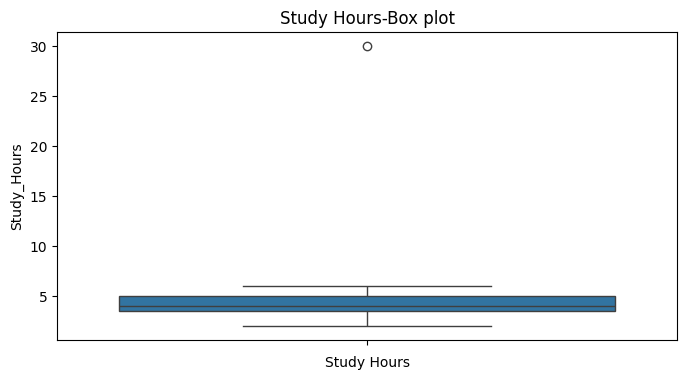

In [7]:
plt.figure(figsize=(8,4))
sns.boxplot(df["Study_Hours"])
plt.title("Study Hours-Box plot")
plt.xlabel("Study Hours")
plt.show


In [8]:
q1=df["Study_Hours"].quantile(0.25)
q3=df["Study_Hours"].quantile(0.75)
print("q1:",q1)
print("q3:",q3)


q1: 3.5
q3: 5.0


In [9]:
IQ3=q3-q1
print("IQ3:",IQ3)


IQ3: 1.5


In [10]:
lower_bound=q1-(1.5*IQ3)
upper_bound=q3+(1.5*IQ3)
print("Lower bound:",lower_bound)
print("Upper bound:",upper_bound)

Lower bound: 1.25
Upper bound: 7.25


In [11]:
outliers_iqr=df[(df["Study_Hours"]<lower_bound) | (df["Study_Hours"]>upper_bound)]
print("IQR Outliers:")
print(outliers_iqr)

IQR Outliers:
   Student  Study_Hours
13       N           30


In [12]:
normal_data_iqr=df[(df["Study_Hours"]>=lower_bound) & (df["Study_Hours"]<=upper_bound)]
print("Normal Data(IQR):")
print(normal_data_iqr)

Normal Data(IQR):
   Student  Study_Hours
0        A            2
1        B            3
2        C            4
3        D            5
4        E            4
5        F            6
6        H            5
7        G            3
8        I            4
9        J            5
10       K            6
11       L            4
12       M            5
14       O            3


In [13]:
df["Z_Score"]=zscore(df["Study_Hours"])
print("Dataset with Z-Score:")
display(df)

Dataset with Z-Score:


,Student,Study_Hours,Z_Score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,H,5,-0.143006
7,G,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [14]:
z_outliers=df[(df["Z_Score"]<-3) | (df["Z_Score"]>3)]
print("Z-Score Outliers:")
print(z_outliers)

Z-Score Outliers:
   Student  Study_Hours   Z_Score
13       N           30  3.687515


In [15]:
df_without_outliers=df[(df["Z_Score"]>=-3) & (df["Z_Score"]<=3)]
print("Dataset without Outliers:")
print(df_without_outliers)

Dataset without Outliers:
   Student  Study_Hours   Z_Score
0        A            2 -0.602669
1        B            3 -0.449448
2        C            4 -0.296227
3        D            5 -0.143006
4        E            4 -0.296227
5        F            6  0.010215
6        H            5 -0.143006
7        G            3 -0.449448
8        I            4 -0.296227
9        J            5 -0.143006
10       K            6  0.010215
11       L            4 -0.296227
12       M            5 -0.143006
14       O            3 -0.449448


In [16]:
df_capped=df.copy()
df_capped["Study_Hours"]=df_capped["Study_Hours"].clip(lower=lower_bound,upper=upper_bound)
print("Dataset with capped values:")
print(df_capped)

Dataset with capped values:
   Student  Study_Hours   Z_Score
0        A         2.00 -0.602669
1        B         3.00 -0.449448
2        C         4.00 -0.296227
3        D         5.00 -0.143006
4        E         4.00 -0.296227
5        F         6.00  0.010215
6        H         5.00 -0.143006
7        G         3.00 -0.449448
8        I         4.00 -0.296227
9        J         5.00 -0.143006
10       K         6.00  0.010215
11       L         4.00 -0.296227
12       M         5.00 -0.143006
13       N         7.25  3.687515
14       O         3.00 -0.449448


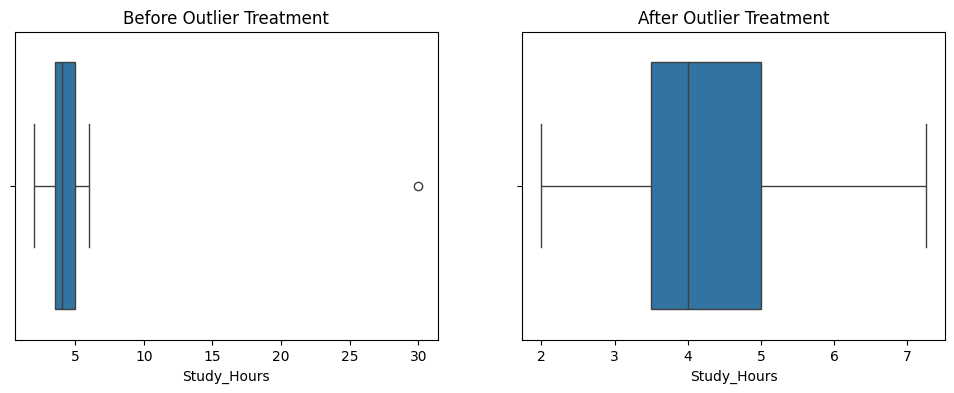

In [17]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x=df["Study_Hours"])
plt.title("Before Outlier Treatment")
plt.subplot(1, 2, 2)
sns.boxplot(x=df_capped["Study_Hours"])
plt.title("After Outlier Treatment")
plt.show()